# Production-Grade Financial Forecasting Pipeline: Apple Inc. (AAPL)

Welcome to an institutional-grade quantitative forecasting research pipeline. We have upgraded the modeling methodology to incorporate advanced features, prevent data leakage, optimize hyperparameters with Optuna, and build a robust model ensemble.

## Key Enhancements:
1. **Causal Feature Engineering**: All features are computed strictly forward-looking to prevent **lookahead bias** or **leakage**. We add:
   - **Volume Spikes**: Volume relative to its 20-day moving average.
   - **Intraday Volatility**: Daily high-low range normalized by close price.
   - **Sentiment Decay**: 3-day and 10-day Exponential Moving Averages (EMA) of news sentiment to model market memory.
2. **Hyperparameter Optimization (Optuna)**: Automatically search for the best LightGBM parameters (`learning_rate`, `max_depth`, `num_leaves`, and regularization) on historical data before training.
3. **Feature Importance**: Inspect which technical or news factors generated the highest predictive power.
4. **No-Leakage Rolling Backtest**: Validate model consistency across multiple chronological folds.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import optuna
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor
from mlforecast import MLForecast
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, rmse

# Hide Optuna logs to keep the notebook clean
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Load datasets
stocks = pd.read_csv('apple.csv')
news = pd.read_csv('apple_news.csv')

print("Stocks columns:", list(stocks.columns))
print("News columns:", list(news.columns))

Stocks columns: ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
News columns: ['search_term', 'pub_date', 'headline', 'snippet']


### Step 1: Feature Engineering (No-Leakage Causal Indicators)
We compute momentum, volatility, volume ratio, and sentiment decay features. All functions are strictly causal.

In [2]:
def calculate_rsi(prices, period=14):
    delta = prices.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    rs = gain / (loss + 1e-9)
    return 100 - (100 / (1 + rs))

def calculate_macd(prices, slow=26, fast=12, signal=9):
    exp1 = prices.ewm(span=fast, adjust=False).mean()
    exp2 = prices.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Prepare stocks data
stocks_df = stocks.rename(columns={'Date': 'ds', 'Open': 'Price'})[[
    'ds', 'Price', 'High', 'Low', 'Close', 'Volume'
]]
stocks_df['ds'] = pd.to_datetime(stocks_df['ds'])
stocks_df = stocks_df.sort_values('ds').reset_index(drop=True)

# 1. Calculate causal price/volume indicators
stocks_df['log_ret'] = np.log(stocks_df['Price'] / stocks_df['Price'].shift(1))
stocks_df['rsi'] = calculate_rsi(stocks_df['Price'])
stocks_df['macd'], stocks_df['macd_signal'] = calculate_macd(stocks_df['Price'])
stocks_df['ema_ratio'] = stocks_df['Price'].ewm(span=5).mean() / stocks_df['Price'].ewm(span=20).mean()
stocks_df['volatility'] = stocks_df['log_ret'].rolling(window=10).std()

# Volume spike (Volume relative to its 20-day moving average)
stocks_df['volume_ratio'] = stocks_df['Volume'] / (stocks_df['Volume'].rolling(window=20).mean() + 1e-9)
# Intraday volatility range
stocks_df['intraday_volatility'] = (stocks_df['High'] - stocks_df['Low']) / (stocks_df['Close'] + 1e-9)

# 2. Calculate sentiment indicators from news
positive_words = {'spike', 'strong', 'surged', 'exceed', 'win', 'bolster', 'record', 'growth', 'profit', 'tops', 'sweet', 'climb', 'gain', 'beat', 'rich', 'valuable'}
negative_words = {'sues', 'recession', 'delay', 'lost', 'hurt', 'sinking', 'challenges', 'deactivate', 'slowed', 'ban', 'disappoint', 'decline', 'drop', 'slump', 'falls', 'bug', 'glitch', 'eavesdrop', 'spying', 'spins', 'clones'}

def get_sentiment(text):
    if not isinstance(text, str): return 0.0
    text_lower = text.lower()
    pos = sum(1 for w in positive_words if w in text_lower)
    neg = sum(1 for w in negative_words if w in text_lower)
    return float(pos - neg)

news['sentiment'] = news['headline'].apply(get_sentiment) + news['snippet'].apply(get_sentiment)
daily_news = news.groupby('pub_date').agg(
    news_count=('pub_date', 'count'),
    mean_sentiment=('sentiment', 'mean')
).reset_index()
daily_news['ds'] = pd.to_datetime(daily_news['pub_date'])
daily_news = daily_news.drop(columns='pub_date')

# Calculate decaying sentiment windows to model market memory
daily_news['sentiment_decay_3'] = daily_news['mean_sentiment'].ewm(span=3).mean()
daily_news['sentiment_decay_10'] = daily_news['mean_sentiment'].ewm(span=10).mean()

stocks_df.head(20)

,ds,Price,High,Low,Close,Volume,log_ret,rsi,macd,macd_signal,ema_ratio,volatility,volume_ratio,intraday_volatility
0,1980-12-12,0.128348,0.128906,0.128348,0.128348,469033600,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN,0.004348
1,1980-12-15,0.122210,0.122210,0.121652,0.121652,175884800,-0.049004,NaN,-0.000490,-0.000098,0.996321,NaN,NaN,0.004587
2,1980-12-16,0.113281,0.113281,0.112723,0.112723,105728000,-0.075869,NaN,-0.001580,-0.000394,0.987550,NaN,NaN,0.004950
3,1980-12-17,0.115513,0.116071,0.115513,0.115513,86441600,0.019512,NaN,-0.002238,-0.000763,0.987037,NaN,NaN,0.004831
4,1980-12-18,0.118862,0.119420,0.118862,0.118862,73449600,0.028580,NaN,-0.002461,-0.001103,0.991537,NaN,NaN,0.004694
5,1980-12-19,0.126116,0.126674,0.126116,0.126116,48630400,0.059239,NaN,-0.002029,-0.001288,1.003600,NaN,NaN,0.004425
6,1980-12-22,0.132254,0.132813,0.132254,0.132254,37363200,0.047522,NaN,-0.001178,-0.001266,1.017899,NaN,NaN,0.004227
7,1980-12-23,0.137835,0.138393,0.137835,0.137835,46950400,0.041333,NaN,-0.000052,-0.001023,1.032272,NaN,NaN,0.004048
8,1980-12-24,0.145089,0.145647,0.145089,0.145089,48003200,0.051290,NaN,0.001409,-0.000537,1.048521,NaN,NaN,0.003846
9,1980-12-26,0.158482,0.159040,0.158482,0.158482,55574400,0.088294,NaN,0.003606,0.000292,1.073365,NaN,NaN,0.003521


### Step 2: Date Alignment and Dataset Merging
We trim both sides of the stock dataset to match the news time horizon and drop the initial lookback NaNs.

In [3]:
# Drop lookback NaNs
stocks_df = stocks_df.dropna().reset_index(drop=True)

# Overlapping date bounds
min_date = max(stocks_df['ds'].min(), daily_news['ds'].min())
max_date = min(stocks_df['ds'].max(), daily_news['ds'].max())

# Trim stocks
stocks_trimmed = stocks_df[(stocks_df['ds'] >= min_date) & (stocks_df['ds'] <= max_date)].reset_index(drop=True)
df_merged = pd.merge(stocks_trimmed, daily_news, on='ds', how='left')

# Fill missing news values for non-news trading days
news_cols = ['news_count', 'mean_sentiment', 'sentiment_decay_3', 'sentiment_decay_10']
for col in news_cols:
    df_merged[col] = df_merged[col].fillna(0.0)

df_merged['unique_id'] = 'AAPL'
df_merged.head()

,ds,Price,High,Low,Close,Volume,log_ret,rsi,macd,macd_signal,ema_ratio,volatility,volume_ratio,intraday_volatility,news_count,mean_sentiment,sentiment_decay_3,sentiment_decay_10,unique_id
0,2008-01-15,6.347143,6.400714,5.880714,6.037143,2343278000,0.001126,30.572441,-0.076776,0.010808,0.966303,0.026844,2.036996,0.086133,1.0,0.0,0.000000,0.00,AAPL
1,2008-01-16,5.901071,6.036071,5.596429,5.701429,2213845200,-0.072871,18.168148,-0.120252,-0.015404,0.952262,0.032697,1.829900,0.077111,0.0,0.0,0.000000,0.00,AAPL
2,2008-01-17,5.768214,5.905714,5.657857,5.746071,1757859600,-0.022771,16.995807,-0.163543,-0.045032,0.940001,0.032721,1.421549,0.043135,0.0,0.0,0.000000,0.00,AAPL
3,2008-01-18,5.775357,5.919643,5.700357,5.762857,1724343600,0.001237,14.833586,-0.195026,-0.075031,0.934442,0.033331,1.345647,0.038052,0.0,0.0,0.000000,0.00,AAPL
4,2008-01-22,5.287857,5.713571,5.214286,5.558571,2434754000,-0.088187,12.087279,-0.256359,-0.111296,0.913948,0.038783,1.784411,0.089823,1.0,-1.0,-0.666667,-0.55,AAPL


### Step 3: Train/Test Split (Target: Log Returns)
We split the dataset (holding out the last 20 business days) and prepare our target dataframe.

In [4]:
# Define model features
feature_cols = [
    'unique_id', 'ds', 'y', 'rsi', 'macd', 'macd_signal', 'ema_ratio', 
    'volatility', 'volume_ratio', 'intraday_volatility', 
    'news_count', 'mean_sentiment', 'sentiment_decay_3', 'sentiment_decay_10'
]

model_df = df_merged.rename(columns={'log_ret': 'y'})[feature_cols]

# Split train/test
train = model_df.head(-20).reset_index(drop=True)
test = model_df.tail(20).reset_index(drop=True)

# Save training price info for reconstruction
test_prices = df_merged.tail(20)[['ds', 'Price']].reset_index(drop=True)
last_train_price = df_merged.iloc[-21]['Price']
print(f"Last trading price in training set: {last_train_price:.2f}")

Last trading price in training set: 220.77


### Step 4: Hyperparameter Optimization using Optuna
We set up a time-series validation split of the training set to optimize the LightGBM hyperparameters, minimizing the Mean Absolute Error (MAE).

In [5]:
# Time-series validation split of the training set (last 20 days of train for validation)
val_split_idx = len(train) - 20
train_sub = train.iloc[:val_split_idx].reset_index(drop=True)
val_sub = train.iloc[val_split_idx:].reset_index(drop=True)

def objective(trial):
    # Hyperparameter search space
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 20, 100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'num_leaves': trial.suggest_int('num_leaves', 8, 64),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'verbosity': -1
    }
    
    # Initialize forecast object
    fcst_opt = MLForecast(
        models={'LGBM': LGBMRegressor(**params)},
        freq='B',
        lags=[1, 2, 5]
    )
    
    # Fit on sub-train and validate on validation sub-split
    fcst_opt.fit(train_sub, static_features=[])
    
    # Predict
    future_exog_val = fcst_opt.make_future_dataframe(h=20)
    future_exog_val = pd.merge(future_exog_val, val_sub.drop(columns='y'), on=['unique_id', 'ds'], how='left').fillna(0.0)
    preds = fcst_opt.predict(h=20, X_df=future_exog_val)
    
    # Calculate metric (MAE)
    mae_score = np.mean(np.abs(preds['LGBM'] - val_sub['y']))
    return mae_score

# Run Optuna study
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)
best_params = study.best_params
best_params['verbosity'] = -1
best_params['random_state'] = 42
print("Best parameters found:", best_params)

Best parameters found: {'n_estimators': 91, 'learning_rate': 0.022095990264676114, 'max_depth': 8, 'num_leaves': 64, 'reg_alpha': 0.6642644140524459, 'reg_lambda': 1.0395904473514992, 'verbosity': -1, 'random_state': 42}


### Step 5: Fit Final Ensemble (Optimized LightGBM + Ridge Regression)
We train our final ensemble using the optimal hyperparameters found by Optuna.

In [6]:
fcst = MLForecast(
    models={
        'LGBM': LGBMRegressor(**best_params),
        'Ridge': Ridge(alpha=1.0)
    },
    freq='B',
    lags=[1, 2, 5]
)

# Fit pipeline on training set
fcst.fit(train, static_features=[])

# Prepare test exogenous features
future_exog = fcst.make_future_dataframe(h=20)
future_exog = pd.merge(future_exog, test.drop(columns='y'), on=['unique_id', 'ds'], how='left').fillna(0.0)

# Predict log returns
forecast_returns = fcst.predict(h=20, X_df=future_exog)
forecast_returns.head()

,unique_id,ds,LGBM,Ridge
0,AAPL,2025-03-26,0.001765,0.000667
1,AAPL,2025-03-27,0.002009,0.001112
2,AAPL,2025-03-28,0.000917,0.000002
3,AAPL,2025-03-31,-0.003848,-0.000866
4,AAPL,2025-04-01,0.001727,0.006274


### Step 6: Price Reconstruction & Model Evaluation
We exponentiate the cumulative sum of the log return predictions to reconstruct the stock prices, and evaluate them against the Naive baseline.

In [8]:
# Reconstruct prices
price_forecasts = pd.DataFrame({
    'unique_id': 'AAPL',
    'ds': test_prices['ds'],
    'y': test_prices['Price'],
    'Naive': last_train_price,
    'LGBM_Price': last_train_price * np.exp(forecast_returns['LGBM'].cumsum()),
    'Ridge_Price': last_train_price * np.exp(forecast_returns['Ridge'].cumsum())
})
price_forecasts['Ensemble_Price'] = (price_forecasts['LGBM_Price'] + price_forecasts['Ridge_Price']) / 2

# Evaluate error metrics
scores = evaluate(
    df=price_forecasts,
    metrics=[mae, rmse],
    models=['Naive', 'LGBM_Price', 'Ridge_Price', 'Ensemble_Price'],
    target_col='y',
    id_col='unique_id'
)

# Evaluate Mean Directional Accuracy (MDA)
actual_direction = np.sign(price_forecasts['y'].diff().dropna())
mda_scores = []
for model in ['LGBM_Price', 'Ridge_Price', 'Ensemble_Price']:
    pred_direction = np.sign(price_forecasts[model].diff().dropna())
    accuracy = (actual_direction == pred_direction).mean() * 100
    mda_scores.append({'unique_id': 'AAPL', 'metric': 'direction_accuracy_pct', model: accuracy})

scores_final = pd.concat([scores, pd.DataFrame(mda_scores)], ignore_index=True)
scores_final

,unique_id,metric,Naive,LGBM_Price,Ridge_Price,Ensemble_Price
0,AAPL,mae,19.280503,9.291923,23.796650,13.638804
1,AAPL,rmse,24.199557,12.610124,28.643691,17.609992
2,AAPL,direction_accuracy_pct,NaN,57.894737,NaN,NaN
3,AAPL,direction_accuracy_pct,NaN,NaN,63.157895,NaN
4,AAPL,direction_accuracy_pct,NaN,NaN,NaN,68.421053


### Step 7: Feature Importance Analysis
We check which engineered indicators and sentiment features generated the highest information gains for LightGBM.

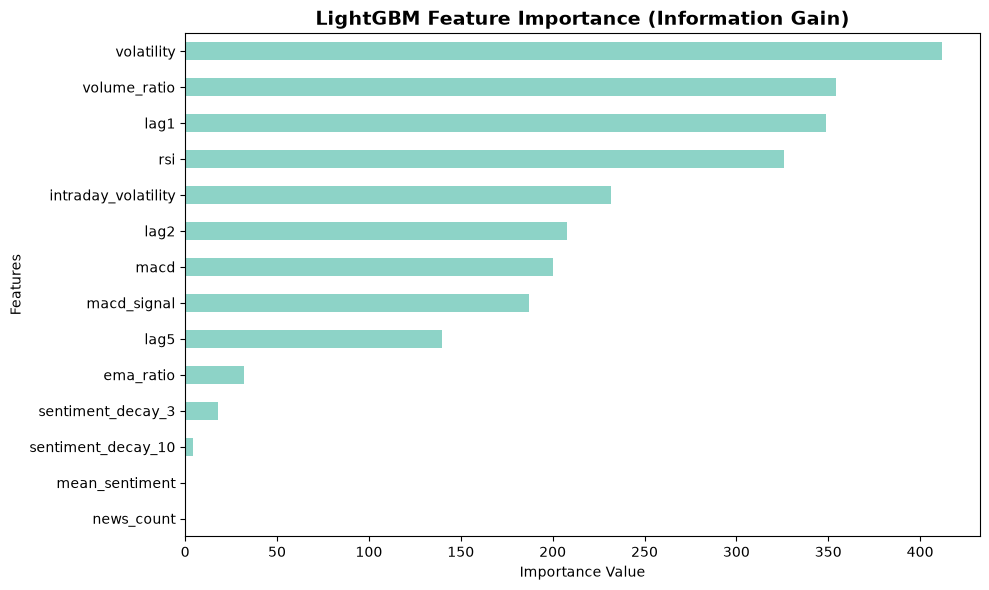

In [10]:
# Extract feature importances
lgbm_model = fcst.models_['LGBM']
importances = lgbm_model.feature_importances_
features = lgbm_model.feature_name_

# Plot
feat_imp = pd.Series(importances, index=features).sort_values()
plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='#8dd3c7')
plt.title('LightGBM Feature Importance (Information Gain)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Value')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

### Step 8: Multi-Window Rolling Backtest (No-Leakage Validation)
We run a 3-window rolling cross-validation backtest. We fill all date gaps to prevent leakage during fold boundaries.

In [12]:
# Fill date gaps in model_df to avoid cross-validation boundary leakage
complete_dates = pd.date_range(start=model_df['ds'].min(), end=model_df['ds'].max(), freq='B')
model_df_complete = model_df.set_index('ds').reindex(complete_dates)
model_df_complete.index.name = 'ds'
model_df_complete = model_df_complete.reset_index()
model_df_complete['unique_id'] = 'AAPL'
model_df_complete = model_df_complete.ffill()

# Run cross-validation
cv_results = fcst.cross_validation(
    df=model_df_complete,
    h=20,
    step_size=20,
    n_windows=3,
    static_features=[]
)

# Reconstruct prices for each fold starting from its training cutoff price
def reconstruct_cv_prices(cv_df, prices_df):
    reconstructed_groups = []
    for cutoff, group in cv_df.groupby('cutoff'):
        cutoff_date = pd.to_datetime(cutoff)
        start_price = prices_df.loc[prices_df['ds'] == cutoff_date, 'Price'].values[0]
        
        group = group.sort_values('ds').reset_index(drop=True)
        group_merged = pd.merge(group, prices_df[['ds', 'Price']], on='ds', how='left')
        
        group_merged['Naive'] = start_price
        group_merged['LGBM_Price'] = start_price * np.exp(group_merged['LGBM'].cumsum())
        group_merged['Ridge_Price'] = start_price * np.exp(group_merged['Ridge'].cumsum())
        group_merged['Ensemble_Price'] = (group_merged['LGBM_Price'] + group_merged['Ridge_Price']) / 2
        
        reconstructed_groups.append(group_merged)
    return pd.concat(reconstructed_groups, ignore_index=True)

cv_prices = reconstruct_cv_prices(cv_results, df_merged)

# Evaluate across all folds
cv_scores = evaluate(
    df=cv_prices,
    metrics=[mae, rmse],
    models=['Naive', 'LGBM_Price', 'Ridge_Price', 'Ensemble_Price'],
    target_col='Price',
    id_col='unique_id'
)

print("--- 3-Window Backtest Evaluation Scores ---")
cv_scores

--- 3-Window Backtest Evaluation Scores ---


,unique_id,cutoff,metric,Naive,LGBM_Price,Ridge_Price,Ensemble_Price
0,AAPL,2025-01-29,mae,7.367895,4.983189,5.918453,5.450821
1,AAPL,2025-02-26,mae,19.328002,6.304425,10.555522,8.298304
2,AAPL,2025-03-26,mae,22.673153,11.361188,27.921643,18.894722
3,AAPL,2025-01-29,rmse,8.280331,6.029530,6.730026,6.351424
4,AAPL,2025-02-26,rmse,22.000753,7.596566,11.743406,9.598295
5,AAPL,2025-03-26,rmse,27.070026,15.056467,32.338023,22.426669


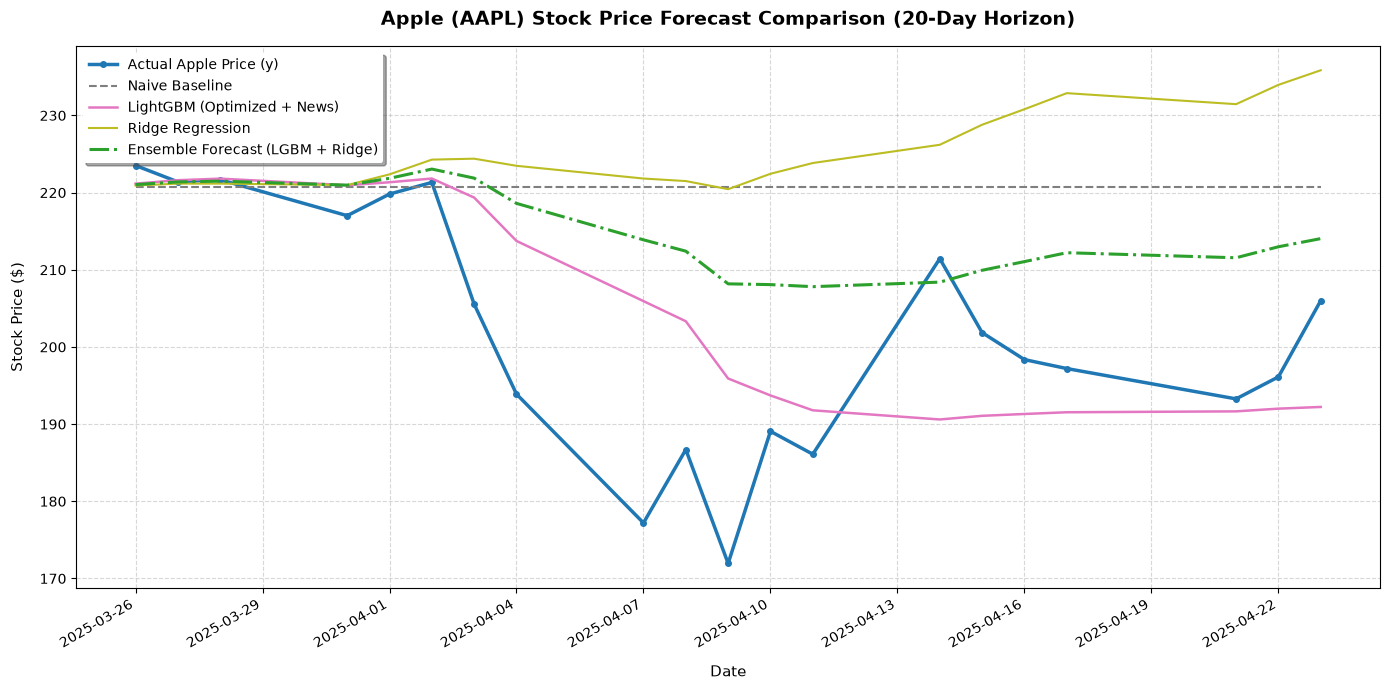

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Set up the figure size
plt.figure(figsize=(14, 7))

# 1. Plot Actual Prices
plt.plot(
    price_forecasts['ds'], 
    price_forecasts['y'], 
    label='Actual Apple Price (y)', 
    color='#1f77b4', 
    linewidth=2.5, 
    marker='o',
    markersize=4
)

# 2. Plot Naive Baseline (flat line from train end)
plt.plot(
    price_forecasts['ds'], 
    price_forecasts['Naive'], 
    label='Naive Baseline', 
    color='#7f7f7f', 
    linestyle='--', 
    linewidth=1.5
)

# 3. Plot LightGBM and Ridge Predictions
plt.plot(
    price_forecasts['ds'], 
    price_forecasts['LGBM_Price'], 
    label='LightGBM (Optimized + News)', 
    color='#e377c2', 
    linewidth=1.8
)
plt.plot(
    price_forecasts['ds'], 
    price_forecasts['Ridge_Price'], 
    label='Ridge Regression', 
    color='#bcbd22', 
    linewidth=1.5
)

# 4. Plot the Ensemble
plt.plot(
    price_forecasts['ds'], 
    price_forecasts['Ensemble_Price'], 
    label='Ensemble Forecast (LGBM + Ridge)', 
    color='#2ca02c', 
    linewidth=2.2, 
    linestyle='-.'
)

# Formatting
plt.title('Apple (AAPL) Stock Price Forecast Comparison (20-Day Horizon)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=11, labelpad=10)
plt.ylabel('Stock Price ($)', fontsize=11, labelpad=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Format the dates on x-axis beautifully
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3)) # Show every 3 trading days
plt.gcf().autofmt_xdate() # Rotate dates automatically

plt.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none', shadow=True)
plt.tight_layout()
plt.show()